# ТК 7-8 (ПР4): бинарная логистическая регрессия
бинарная логистическая регрессия - это статистическая модель для оценки вероятности принадлежности объекта к одному из двух классов с помощью линейной комбинации признаков и сигмоидной функции.

Пример из методички (расходы на рекламу) + договоры insclass: сравнение двух способов обучения бинарной логистической регрессии.

## Импорты

In [1]:
import os
import sys
import time
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from logistic_regression import LogisticRegressionGD
from data_pipeline import load_clean_split, scaled_matrix

## Данные примера

Термином «метод наименьших квадратов (МНК)» называют то, что метод оценки параметров линейной модели, минимизирующий сумму квадратов отклонений предсказаний от наблюдаемых значений.

выбросы - это наблюдения, существенно отличающиеся от основной массы данных и способные искажать оценки параметров модели.

Термином «сигмоида» называют то, что гладкая S-образная функция, переводящая любое вещественное значение в интервал (0, 1) и используемая в логистической регрессии для моделирования вероятности.

На scatter-диаграмме ниже по оси X отложены расходы на рекламу, а по оси Y — бинарный эффект. Каждая точка соответствует одному наблюдению, а выбросы с большими значениями x легко заметить в правой части графика.

В данных есть выбросы x=100 и x=200. Они сильно влияют на МНК; логистическая кривая устойчивее.

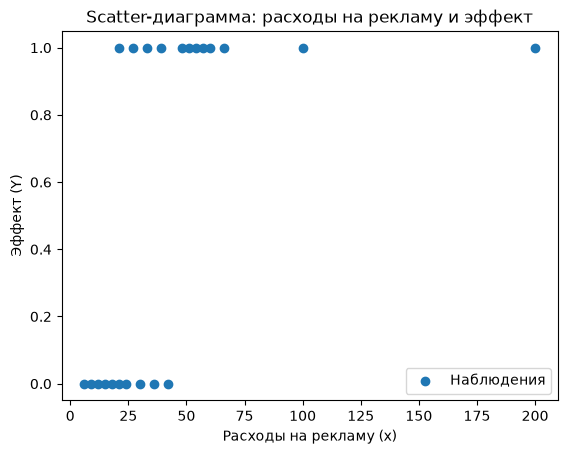

In [2]:
# x — расходы на рекламу, Y — эффект (0/1)
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
plt.scatter(x, Y, label="Наблюдения")
plt.title("Scatter-диаграмма: расходы на рекламу и эффект")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Эффект (Y)")
plt.legend()

## МНК и логистическая регрессия

МНК даёт значения вне [0,1] и чувствителен к выбросам. Для бинарного отклика используем логистическую регрессию.

На следующем графике красная прямая показывает аппроксимацию данных методом наименьших квадратов. Обратите внимание, что предсказанные значения могут выходить за допустимый для вероятностей диапазон [0, 1], что демонстрирует ограничение МНК для бинарного отклика.

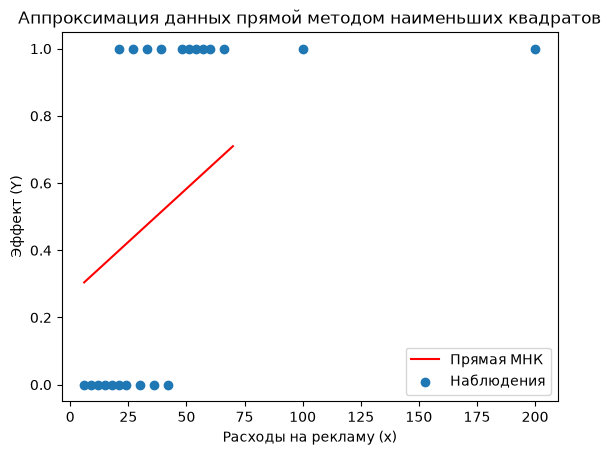

In [3]:
# МНК; чувствителен к выбросам x=100, 200
a1 = ((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a0 = Y.mean() - a1 * x.mean()
x_space = np.linspace(6, 70, 20)
Y_pred = a0.item() + a1.item() * x_space
plt.plot(x_space, Y_pred, 'r', label="Прямая МНК")
plt.scatter(x, Y, label="Наблюдения")
plt.title("Аппроксимация данных прямой методом наименьших квадратов")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Эффект (Y)")
plt.legend()

## Обучение моделей

Термином «intercept (свободный член / константный признак)» называют то, что дополнительный признак, равный единице, который позволяет линейной модели сдвигать решение независимо от значений входных переменных.

функция правдоподобия (LL) - это функция, измеряющая вероятность наблюдаемых данных при заданных параметрах модели; максимизация LL эквивалентна подбору параметров под выборку.

кросс-энтропия (CE) - это функция потерь, равная отрицанию логарифма правдоподобия для бинарной классификации; её минимизация соответствует максимизации правдоподобия.

градиентный спуск/подъём - это итерационные методы оптимизации, на каждом шаге изменяющие параметры модели в направлении, противоположном (спуск) или совпадающем (подъём) с градиентом целевой функции.

Далее к матрице признаков добавляется константный столбец intercept, после чего модели обучаются двумя способами: подъёмом правдоподобия (LL) и спуском по кросс-энтропии (CE).

In [4]:
# Intercept-столбец: свободный сдвиг сигмоиды
x_ = x.copy()
intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis=1))

start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE = regr_CE.fit(x_, Y, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="CE")
print(f"Время обучения CE: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL = regr_LL.fit(x_, Y, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="LL")
print(f"Время обучения LL: {time.time() - start_time_LL} сек.")

Время обучения CE: 0.07851886749267578 сек.
Время обучения LL: 0.07651495933532715 сек.


## Предсказания моделей

На двух соседних scatter-графиках сравниваются истинные метки эффекта и предсказанные моделями CE и LL вероятности положительного класса. По оси X отложены расходы на рекламу, по оси Y — вероятность эффекта; чем ближе цветная точка к значению истинной метки, тем точнее предсказание.

array([[-3.59901953],
       [ 0.11215758]])

array([[-3.59901953],
       [ 0.11215758]])

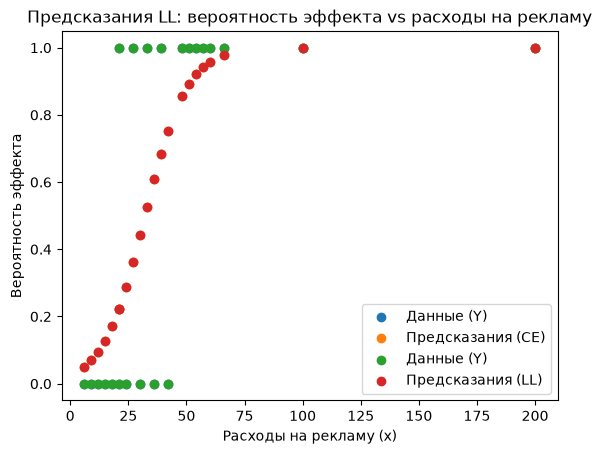

In [5]:
# Предсказания и коэффициенты CE и LL
plt.scatter(x, Y, label="Данные (Y)")
plt.scatter(x, regr_CE.predict(x_), label="Предсказания (CE)")
plt.title("Предсказания CE: вероятность эффекта vs расходы на рекламу")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Вероятность эффекта")
plt.legend()
display(regr_CE.coefs())
plt.scatter(x, Y, label="Данные (Y)")
plt.scatter(x, regr_LL.predict(x_), label="Предсказания (LL)")
plt.title("Предсказания LL: вероятность эффекта vs расходы на рекламу")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Вероятность эффекта")
plt.legend()
display(regr_LL.coefs())

## Сравнение кривых обучения и метрик

Термином «кривая обучения» называют то, что график зависимости значения функции потерь или ошибки модели от номера итерации обучения, показывающий процесс сходимости оптимизации.

accuracy (доля правильных ответов) - это доля объектов, для которых модель предсказала класс, совпавший с истинной меткой.

Термином «precision (точность)» называют то, что доля объектов, отнесённых моделью к положительному классу, которые действительно являются положительными.

Термином «recall (полнота)» называют то, что доля объектов положительного класса, которые модель правильно распознала.

Термином «F1-мера» называют то, что среднее гармоническое precision и recall, объединяющее точность и полноту в одну числовую метрику качества.

На графике ниже по горизонтали отложены номера итераций градиентного спуска/подъёма, а по вертикали — значение ошибки CE и LL. Убывание обеих кривых показывает сходимость обучения, а близость кривых иллюстрирует эквивалентность CE и LL для данной задачи.

В текстовом выводе приведены accuracy, precision, recall и F1-мера на обучающей выборке для CE и LL.

CE accuracy: 0    0.818182
dtype: float64 precision: 0.8333333333333334 recall: 0.8333333333333334 f1: 0.8333333333333334
LL accuracy: 0    0.818182
dtype: float64 precision: 0.8333333333333334 recall: 0.8333333333333334 f1: 0.8333333333333334


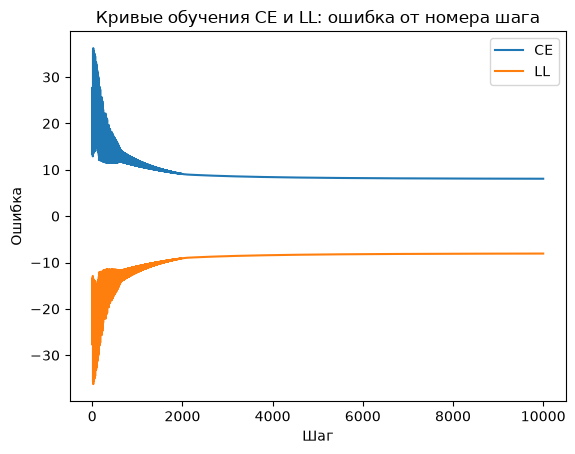

In [6]:
# Сравниваем CE и LL по кривым обучения и метрикам
plt.plot(steps_CE, errors_CE, label="CE")
plt.plot(steps_LL, errors_LL, label="LL")
plt.title("Кривые обучения CE и LL: ошибка от номера шага")
plt.xlabel("Шаг")
plt.ylabel("Ошибка")
plt.legend()
for tag, m in [("CE", regr_CE), ("LL", regr_LL)]:
    print(tag, "accuracy:", m.accuracy(x_, Y), "precision:", m.precision(x_, Y), "recall:", m.recall(x_, Y), "f1:", m.f1(x_, Y))

## Данные insclass

отложенная выборка (валидационная и тестовая) - это часть исходных данных, исключаемая из обучения и используемая для настройки гиперпараметров (валидационная) и окончательной проверки качества модели (тестовая).

Страховые договоры: 151406 строк, 10 числовых признаков + target. Тестового файла нет — отложенная выборка 70/15/15.

In [7]:
TRAIN_CSV = os.path.join("docs", "insclass_train.csv")
train, validate, test, scaler = load_clean_split(TRAIN_CSV)
print(len(train), len(validate), len(test))
train.describe()

102570 21979 21980


,variable_4,variable_6,variable_12,variable_13,variable_14,variable_16,variable_17,variable_18,variable_19,variable_27,target
count,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000
mean,11.386858,117.694764,133.191032,49.977325,87.449536,132.203073,81.784429,109.263724,139.957882,15.546701,0.082539
std,6.910702,50.007569,87.880125,15.481846,32.178495,42.412603,12.375472,67.490633,18.592180,11.992183,0.275185
min,2.000000,1.000000,0.000000,20.731525,80.985224,28.130592,80.985224,19.287400,102.172584,0.000000,0.000000
25%,6.000000,86.000000,66.827923,38.519899,80.985224,98.648082,80.985224,80.985224,127.113159,6.447149,0.000000
50%,10.000000,107.000000,121.261910,46.438089,80.985224,118.116608,80.985224,80.985224,148.905712,12.200897,0.000000
75%,14.000000,137.000000,175.818287,59.293870,80.985224,162.514016,80.985224,139.401847,148.905712,20.731525,0.000000
max,80.000000,1975.000000,842.774591,114.436034,273.413449,214.256572,273.413449,376.183487,284.372991,95.869364,1.000000


## Масштабирование признаков

Термином «StandardScaler» называют то, что метод масштабирования признаков путём вычитания среднего и деления на стандартное отклонение, приводящий распределение к нулевому среднему и единичной дисперсии.

Термином «утечка данных (data leakage)» называют то, что ситуация, когда в обучение модели попадает информация из валидационной или тестовой выборки, что приводит к завышенной оценке качества.

Признаки insclass масштабируются только по обучающей выборке, чтобы исключить утечку информации о валидационной и тестовой частях.

In [8]:
# StandardScaler fit только на train, чтобы не допустить утечки.
# 10000 шагов, как в методичке.
Xtr, ytr = scaled_matrix(train, scaler)
Xva, yva = scaled_matrix(validate, scaler)
m_ll, m_ce = LogisticRegressionGD(), LogisticRegressionGD()
t0 = time.time(); m_ll.fit(Xtr, ytr, max_steps=10000, Rtype="LL"); t_ll = time.time() - t0
t0 = time.time(); m_ce.fit(Xtr, ytr, max_steps=10000, Rtype="CE"); t_ce = time.time() - t0
for tag, m, t in [("LL", m_ll, t_ll), ("CE", m_ce, t_ce)]:
    print(tag, f"{t:.1f} сек.", "train f1:", m.f1(Xtr, ytr), "validate accuracy:", float(np.asarray(m.accuracy(Xva, yva)).mean()), "validate f1:", m.f1(Xva, yva))

LL 12.9 сек. train f1: 0.0 validate accuracy: 0.9167842031029619 validate f1: 0.0
CE 14.5 сек. train f1: 0.0 validate accuracy: 0.9167842031029619 validate f1: 0.0


## Выводы
дисбаланс классов - это ситуация в задаче классификации, при которой количество объектов разных классов существенно различается, что затрудняет обучение и интерпретацию метрик.

- Пример: LL и CE дают одинаковые коэффициенты (~-3.60 и ~0.11) и accuracy ~0.82 при F1 ~0.83; время ~0.2 с.
- insclass: обучение ~29 с на вариант; accuracy ~0.92 на train и validate, но F1 = 0 — модель предсказывает одни нули.
- Нулевой F1 при высокой accuracy — следствие дисбаланса (рисковых ~8%); accuracy здесь не показательна.
- Файл insclass_test.csv в архиве отсутствует, поэтому вместо него отложенная выборка 70/15/15.